In [16]:
%pip -q install kagglehub tqdm

import os
from pathlib import Path
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

import kagglehub
from PIL import Image



##1. Download the dataset and load the target columns

In [17]:
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

DATA_PATH = os.path.join(path, "HAM10000_metadata.csv")
if not os.path.isfile(DATA_PATH):
    raise FileNotFoundError(f"Metadata file not found: {DATA_PATH}")

print("Dataset directory:", path)
print("Metadata file:", DATA_PATH)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset directory: /kaggle/input/skin-cancer-mnist-ham10000
Metadata file: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv


In [18]:
# Load only the columns required for image-target validation.
df = pd.read_csv(DATA_PATH, usecols=["image_id", "dx"])
df["image_id"] = df["image_id"].astype("string").str.strip()
df["dx"] = df["dx"].astype("string").str.strip().str.lower()
df.loc[df["dx"] == "", "dx"] = pd.NA

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
IMAGE_DIRS = [
    os.path.join(path, "HAM10000_images_part_1"),
    os.path.join(path, "HAM10000_images_part_2"),
]

# Fail clearly if the expected uppercase folders are not present.
missing_dirs = [folder for folder in IMAGE_DIRS if not os.path.isdir(folder)]
if missing_dirs:
    raise FileNotFoundError(
        "Expected image folder(s) not found: " + ", ".join(missing_dirs)
    )

# Search only inside the two selected folders; do not scan the dataset root.
image_files = sorted(
    p for folder in IMAGE_DIRS
    for p in Path(folder).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not image_files:
    raise FileNotFoundError(
        "No JPG, JPEG, or PNG images were found in the two expected image folders."
    )

# Keep one path per image ID as a safeguard against duplicates within selected folders.
paths_by_stem = {}
for image_path in image_files:
    paths_by_stem.setdefault(image_path.stem, []).append(image_path)

image_map = {stem: paths[0] for stem, paths in paths_by_stem.items()}
duplicate_file_stems = {
    stem: paths for stem, paths in paths_by_stem.items() if len(paths) > 1
}

df["image_path"] = df["image_id"].map(image_map)

print(f"Metadata file: {DATA_PATH}")
print("Image folders checked:")
for folder in IMAGE_DIRS:
    print(f"- {folder}")
print(f"Metadata rows with image_id and dx columns: {len(df):,}")
print(f"Image file paths found in the two selected folders: {len(image_files):,}")
print(f"Unique image IDs from filenames: {len(image_map):,}")
print(f"Image IDs duplicated within the selected folders: {len(duplicate_file_stems):,}")

if duplicate_file_stems:
    print("\nExamples of duplicated image IDs within the selected folders:")
    for stem, paths in list(sorted(duplicate_file_stems.items()))[:5]:
        print(f"- {stem}")
        for duplicate_path in paths:
            print(f"  {duplicate_path}")


Metadata file: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Image folders checked:
- /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1
- /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2
Metadata rows with image_id and dx columns: 10,015
Image file paths found in the two selected folders: 10,015
Unique image IDs from filenames: 10,015
Image IDs duplicated within the selected folders: 0


Check whether each unique image has a valid target

In [19]:
has_target = df["dx"].notna() & df["dx"].ne("")
has_image = df["image_path"].notna()

# Count each image ID only once, even if multiple paths exist within the selected folders.
valid_pairs = (
    df.loc[has_target & has_image, ["image_id", "dx", "image_path"]]
    .drop_duplicates(subset=["image_id"])
    .copy()
)

missing_image_rows = int((~has_image).sum())
missing_target_rows = int((~has_target).sum())
duplicate_metadata_ids = int(df["image_id"].duplicated().sum())
class_counts = valid_pairs["dx"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "image_count": class_counts,
    "percentage": (class_counts / len(valid_pairs) * 100).round(2)
})

summary = pd.DataFrame({
    "Check": [
        "Image file paths found in the two selected folders",
        "Unique image IDs found in filenames",
        "Metadata rows",
        "Rows matched to an image file",
        "Rows with missing target label",
        "Rows with no matching image file",
        "Duplicate image_id rows in metadata",
        "Image IDs duplicated within the selected folders",
        "Unique matched images with a target",
        "Number of target classes"
    ],
    "Result": [
        len(image_files),
        len(image_map),
        len(df),
        int(has_image.sum()),
        missing_target_rows,
        missing_image_rows,
        duplicate_metadata_ids,
        len(duplicate_file_stems),
        len(valid_pairs),
        int(valid_pairs["dx"].nunique())
    ]
})

display(summary)
print("\nTarget distribution among unique, matched image-target pairs:")
display(class_summary.rename_axis("dx"))



,Check,Result
0,Image file paths found in the two selected fol...,10015
1,Unique image IDs found in filenames,10015
2,Metadata rows,10015
3,Rows matched to an image file,10015
4,Rows with missing target label,0
5,Rows with no matching image file,0
6,Duplicate image_id rows in metadata,0
7,Image IDs duplicated within the selected folders,0
8,Unique matched images with a target,10015
9,Number of target classes,7



Target distribution among unique, matched image-target pairs:


,image_count,percentage
dx,,
akiec,327,3.27
bcc,514,5.13
bkl,1099,10.97
df,115,1.15
mel,1113,11.11
nv,6705,66.95
vasc,142,1.42


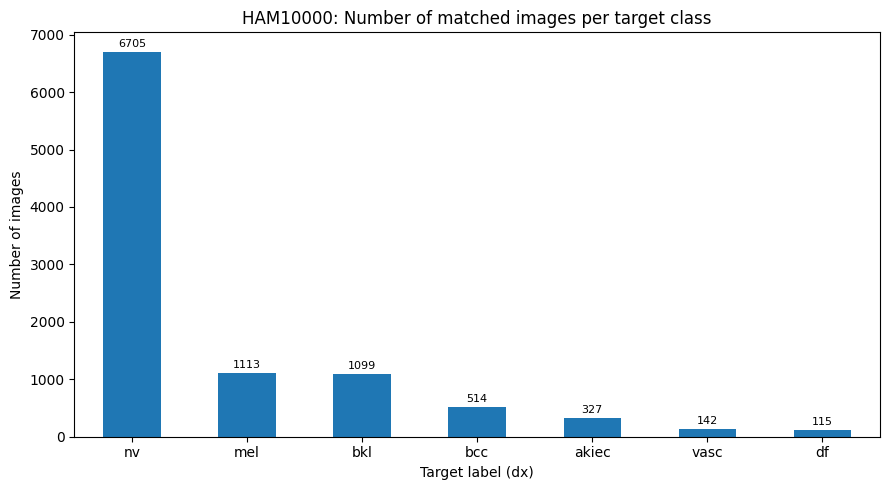

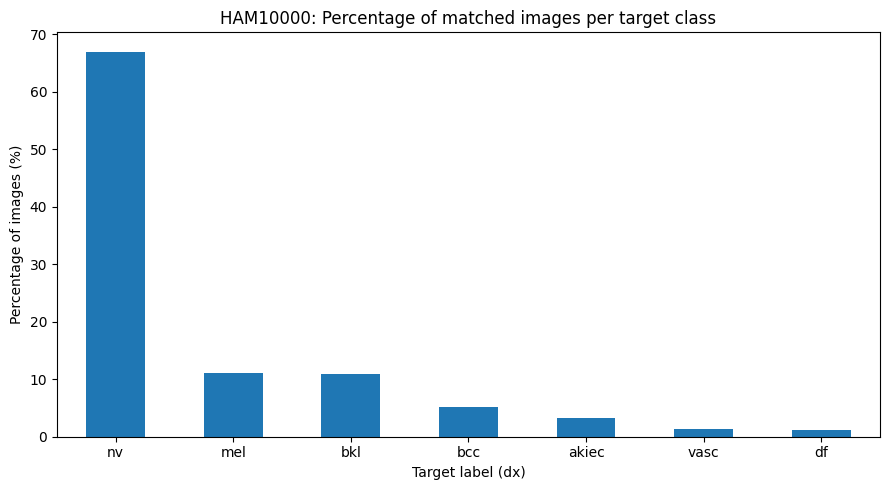

In [20]:
# Plot counts per target class.
fig, ax = plt.subplots(figsize=(9, 5))
class_counts.sort_values(ascending=False).plot(kind="bar", ax=ax)
ax.set_title("HAM10000: Number of matched images per target class")
ax.set_xlabel("Target label (dx)")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

# Plot percentages as a second view of class imbalance.
fig, ax = plt.subplots(figsize=(9, 5))
(class_counts / len(valid_pairs) * 100).sort_values(ascending=False).plot(
    kind="bar", ax=ax
)
ax.set_title("HAM10000: Percentage of matched images per target class")
ax.set_xlabel("Target label (dx)")
ax.set_ylabel("Percentage of images (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## Visualize representative images from every target class

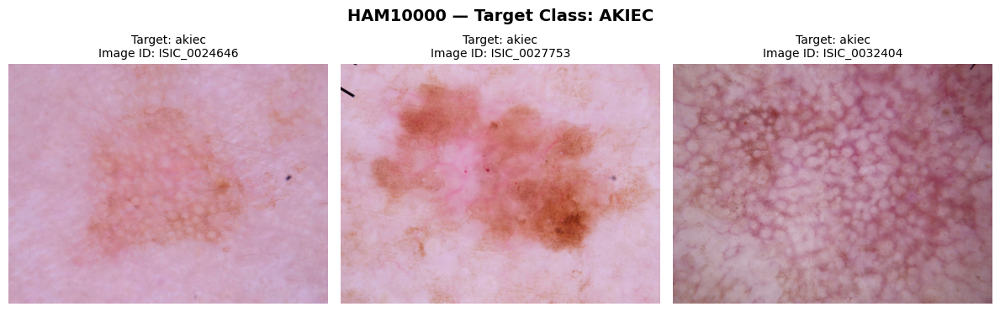

Target 'akiec': 327 images available


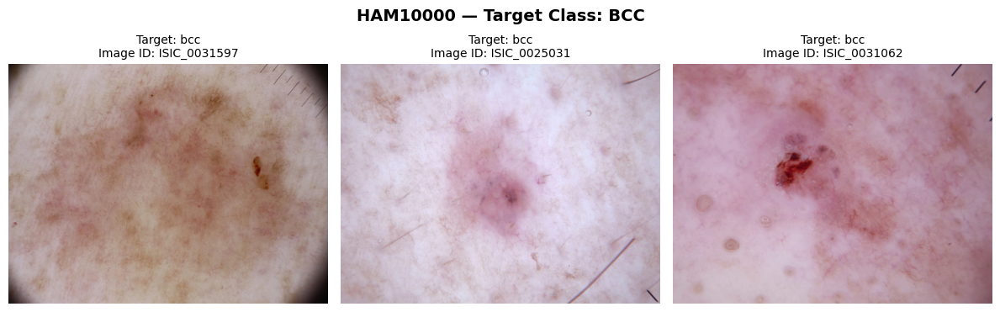

Target 'bcc': 514 images available


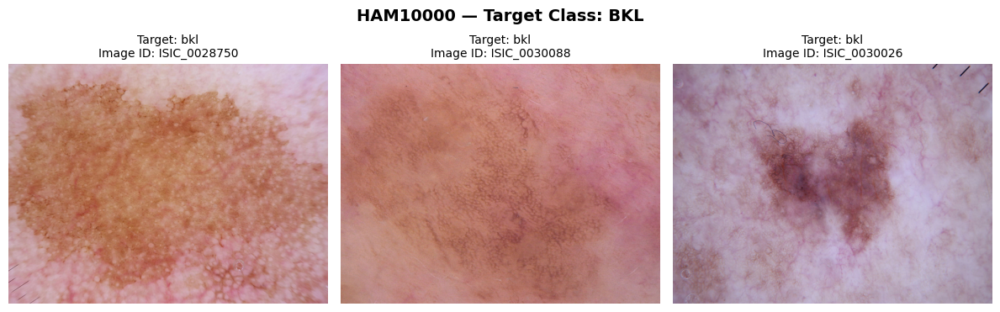

Target 'bkl': 1099 images available


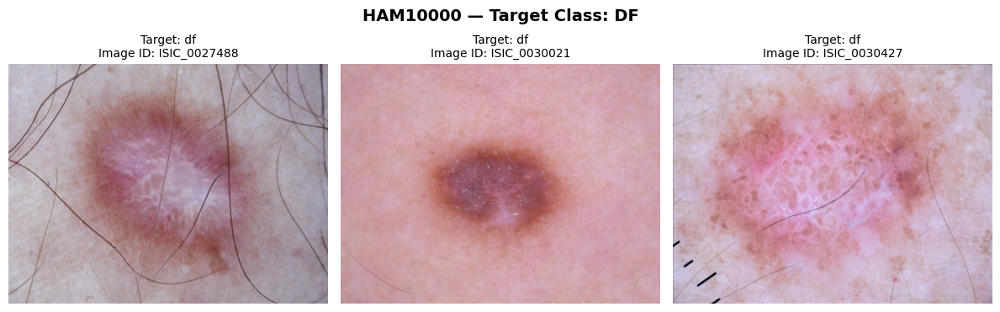

Target 'df': 115 images available


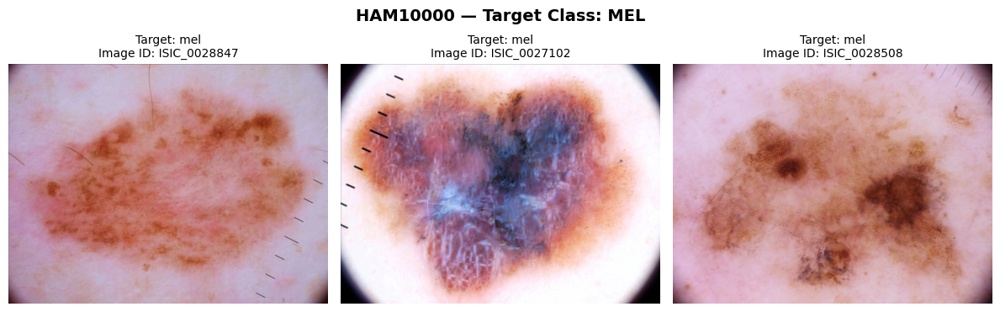

Target 'mel': 1113 images available


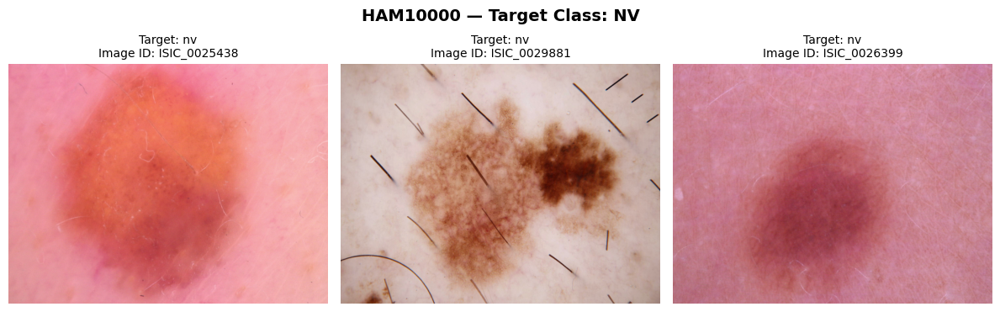

Target 'nv': 6705 images available


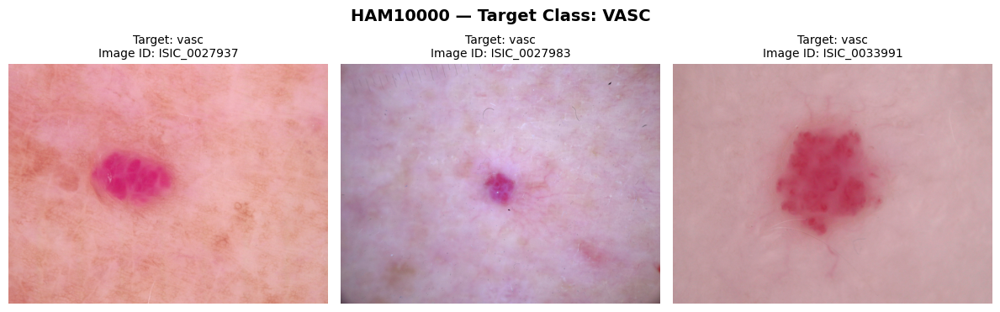

Target 'vasc': 142 images available


In [21]:
N_SAMPLES_PER_CLASS = 3
class_labels = sorted(valid_pairs["dx"].dropna().unique())

for label in class_labels:
    # Select images belonging to the current target class
    class_df = valid_pairs[valid_pairs["dx"] == label]

    samples = class_df.sample(
        n=min(N_SAMPLES_PER_CLASS, len(class_df)),
        random_state=42
    ).reset_index(drop=True)

    # Create a separate figure for each target class
    n_samples = len(samples)

    fig, axes = plt.subplots(
        nrows=1,
        ncols=n_samples,
        figsize=(4 * n_samples, 4)
    )

    # Ensure axes is always iterable
    axes = np.atleast_1d(axes)

    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[col_idx]

        with Image.open(sample["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"Target: {label}\nImage ID: {sample['image_id']}",
            fontsize=10
        )
        ax.axis("off")

    fig.suptitle(
        f"HAM10000 — Target Class: {label.upper()}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # Print the number of images available for this class
    print(f"Target '{label}': {len(class_df)} images available")
    fig.savefig(
        f"HAM10000_target_{label}.png",
        dpi=150,
        bbox_inches="tight"
    )

##Export Image

In [22]:
import shutil
from pathlib import Path

# Create output directory structure
DEMO_ROOT = Path("/content/HAM10000_demo_package")
SAMPLES_DIR = DEMO_ROOT / "images_by_class"
CHARTS_DIR = DEMO_ROOT / "charts"

SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

N_DEMO_IMAGES_PER_CLASS = 5
rng = np.random.default_rng(42)
demo_manifest = []

for label, group in valid_pairs.groupby("dx", sort=True):
    n_take = min(N_DEMO_IMAGES_PER_CLASS, len(group))
    # Sample a fixed subset so that subsequent runs are reproducible
    selected_idx = rng.choice(group.index.to_numpy(), size=n_take, replace=False)
    samples = group.loc[selected_idx]

    class_dir = SAMPLES_DIR / str(label)
    class_dir.mkdir(parents=True, exist_ok=True)

    for _, row in samples.iterrows():
        src = Path(row["image_path"])
        dst = class_dir / src.name
        shutil.copy2(src, dst)

        demo_manifest.append({
            "dx": label,
            "image_id": row["image_id"],
            "saved_path": str(dst)
        })

demo_manifest_df = pd.DataFrame(demo_manifest)
demo_manifest_df.to_csv(DEMO_ROOT / "demo_images_manifest.csv", index=False)

print(f"Saved {len(demo_manifest_df)} sample images.")
print(f"Image directory: {SAMPLES_DIR}")
display(demo_manifest_df.groupby("dx").size().rename("saved_images").to_frame())

Saved 35 sample images.
Image directory: /content/HAM10000_demo_package/images_by_class


,saved_images
dx,
akiec,5
bcc,5
bkl,5
df,5
mel,5
nv,5
vasc,5


## Image-property distributions


In [23]:

image_properties = []
failed_image_reads = []

for row in valid_pairs.itertuples(index=False):
    image_path = Path(row.image_path)
    try:
        with Image.open(image_path) as img:
            width, height = img.size
        file_size_kb = image_path.stat().st_size / 1024
        image_properties.append({
            "image_id": row.image_id,
            "dx": row.dx,
            "width": width,
            "height": height,
            "short_side": min(width, height),
            "aspect_ratio": width / height if height else float("nan"),
            "file_size_kb": file_size_kb
        })
    except Exception as exc:
        failed_image_reads.append((str(image_path), str(exc)))

image_props_df = pd.DataFrame(image_properties)

print(f"Images with readable dimensions: {len(image_props_df):,}")
print(f"Images that could not be read: {len(failed_image_reads):,}")
if failed_image_reads:
    print("Examples of unreadable images:")
    for file_path, error in failed_image_reads[:5]:
        print(f"- {file_path}: {error}")

display(image_props_df[[
    "width", "height", "short_side", "aspect_ratio", "file_size_kb"
]].describe().round(2))

Images with readable dimensions: 10,015
Images that could not be read: 0


,width,height,short_side,aspect_ratio,file_size_kb
count,10015.0,10015.0,10015.0,10015.00,10015.00
mean,600.0,450.0,450.0,1.33,270.12
std,0.0,0.0,0.0,0.00,44.79
min,600.0,450.0,450.0,1.33,83.33
25%,600.0,450.0,450.0,1.33,251.18
50%,600.0,450.0,450.0,1.33,270.43
75%,600.0,450.0,450.0,1.33,294.06
max,600.0,450.0,450.0,1.33,479.27


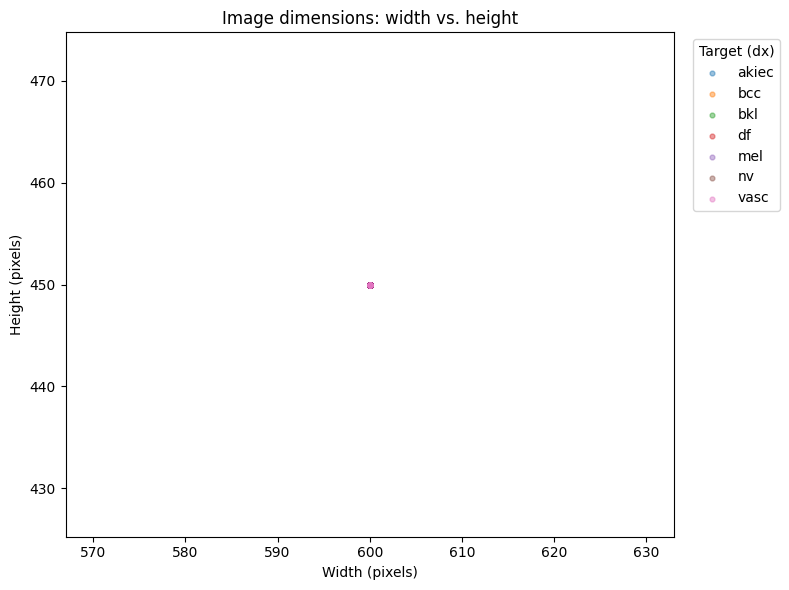

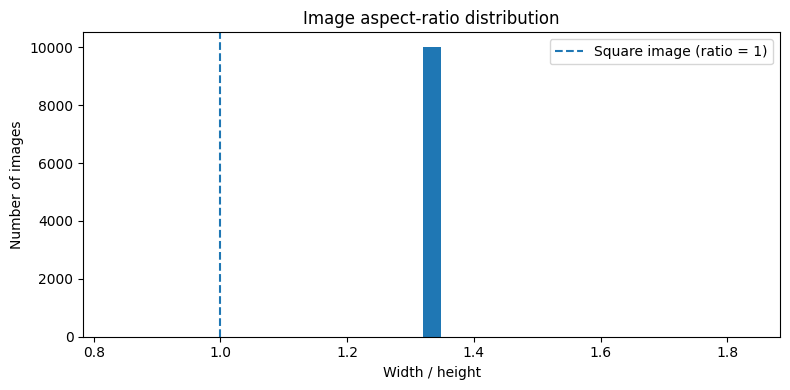

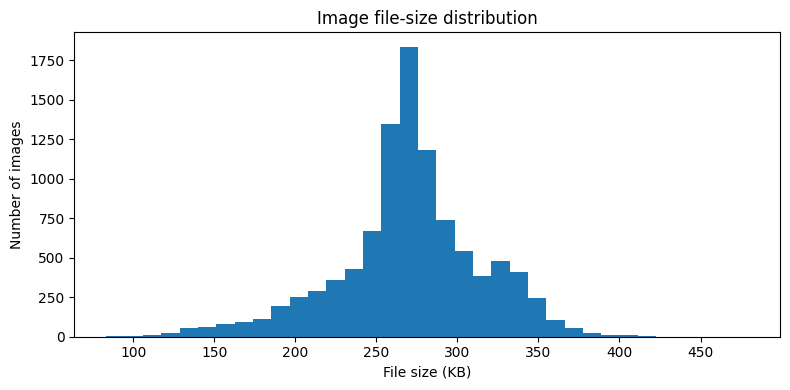

In [24]:
#  Width-versus-height distribution
fig, ax = plt.subplots(figsize=(8, 6))
for label, group in image_props_df.groupby("dx"):
    ax.scatter(
        group["width"], group["height"],
        alpha=0.45, s=12, label=label
    )
ax.set_title("Image dimensions: width vs. height")
ax.set_xlabel("Width (pixels)")
ax.set_ylabel("Height (pixels)")
ax.legend(title="Target (dx)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Aspect-ratio distribution
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(image_props_df["aspect_ratio"].dropna(), bins=35)
ax.axvline(1.0, linestyle="--", label="Square image (ratio = 1)")
ax.set_title("Image aspect-ratio distribution")
ax.set_xlabel("Width / height")
ax.set_ylabel("Number of images")
ax.legend()
plt.tight_layout()
plt.show()


# File-size distribution
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(image_props_df["file_size_kb"].dropna(), bins=35)
ax.set_title("Image file-size distribution")
ax.set_xlabel("File size (KB)")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.show()

## Color distribution
Visualize RGB color distribution across classes

In [25]:
import plotly.express as px

N_COLOR_IMAGES_PER_CLASS = 10
N_PIXELS_PER_IMAGE = 500
rng_color = np.random.default_rng(42)

color_records = []

for label, group in valid_pairs.groupby("dx", sort=True):
    n_take = min(N_COLOR_IMAGES_PER_CLASS, len(group))
    selected_idx = rng_color.choice(group.index.to_numpy(), size=n_take, replace=False)
    selected_images = group.loc[selected_idx]

    for _, row in selected_images.iterrows():
        with Image.open(row["image_path"]) as img:
            rgb = np.asarray(img.convert("RGB"), dtype=np.uint8)

        pixels = rgb.reshape(-1, 3)
        n_pixels = min(N_PIXELS_PER_IMAGE, len(pixels))
        pixel_idx = rng_color.choice(len(pixels), size=n_pixels, replace=False)
        sampled_pixels = pixels[pixel_idx]

        for red, green, blue in sampled_pixels:
            brightness = 0.299 * red + 0.587 * green + 0.114 * blue
            color_records.append({
                "Red": int(red),
                "Green": int(green),
                "Blue": int(blue),
                "Brightness": float(brightness),
                "dx": str(label),
                "image_id": row["image_id"]
            })

rgb_sample_df = pd.DataFrame(color_records)
rgb_sample_df.to_csv(CHARTS_DIR / "rgb_pixel_sample.csv", index=False)

fig_rgb = px.scatter_3d(
    rgb_sample_df,
    x="Red",
    y="Green",
    z="Blue",
    color="Brightness",
    color_continuous_scale="Viridis",
    hover_data=["dx", "image_id"],
    opacity=0.75,
    title="Color Space Distribution (RGB)"
)

fig_rgb.update_traces(marker=dict(size=2.5))
fig_rgb.update_layout(
    scene=dict(
        xaxis_title="Red",
        yaxis_title="Green",
        zaxis_title="Blue"
    ),
    coloraxis_colorbar=dict(title="Brightness"),
    margin=dict(l=0, r=0, b=0, t=45)
)
fig_rgb.show()

# Save the interactive, zoomable HTML chart
fig_rgb.write_html(
    str(CHARTS_DIR / "color_space_rgb_3d.html"),
    include_plotlyjs="cdn"
)
print("Saved RGB chart at:", CHARTS_DIR / "color_space_rgb_3d.html")

Saved RGB chart at: /content/HAM10000_demo_package/charts/color_space_rgb_3d.html


## Image quality metrics
Calculate and visualize image quality metrics

In [26]:


quality_records = []
failed_quality_reads = []

for row in valid_pairs.itertuples(index=False):
    try:
        with Image.open(row.image_path) as img:
            rgb = np.asarray(img.convert("RGB"), dtype=np.uint8)

        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

        brightness = float(np.mean(gray))
        contrast = float(np.std(gray))
        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())

        quality_records.append({
            "image_id": row.image_id,
            "dx": str(row.dx),
            "brightness": brightness,
            "contrast": contrast,
            "sharpness": sharpness
        })
    except Exception as exc:
        failed_quality_reads.append((row.image_id, str(exc)))

image_quality_df = pd.DataFrame(quality_records)
image_quality_df.to_csv(CHARTS_DIR / "image_quality_metrics.csv", index=False)

print(f"Number of images with calculated metrics: {len(image_quality_df):,}")
print(f"Number of unreadable/failed images: {len(failed_quality_reads):,}")

display(
    image_quality_df[["brightness", "contrast", "sharpness"]]
    .describe()
    .round(2)
)

# Average metrics table grouped by each target class
quality_by_class = (
    image_quality_df.groupby("dx")[["brightness", "contrast", "sharpness"]]
    .mean()
    .round(2)
)
display(quality_by_class)
quality_by_class.to_csv(CHARTS_DIR / "image_quality_mean_by_class.csv")

Number of images with calculated metrics: 10,015
Number of unreadable/failed images: 0


,brightness,contrast,sharpness
count,10015.00,10015.00,10015.00
mean,156.56,28.04,79.23
std,19.23,11.36,124.97
min,58.22,5.26,7.62
25%,143.67,19.82,34.37
50%,156.40,26.04,49.24
75%,169.47,34.16,89.46
max,229.89,85.49,3825.02


,brightness,contrast,sharpness
dx,,,
akiec,164.51,23.06,61.07
bcc,168.34,21.70,100.17
bkl,151.93,25.68,95.46
df,166.20,22.04,97.36
mel,150.68,34.47,104.61
nv,156.65,28.20,71.51
vasc,165.21,27.22,70.78


In [27]:
# Sharpness (X) and Contrast (Y) scatter plot, color-coded by target class (dx)
fig_quality = px.scatter(
    image_quality_df,
    x="sharpness",
    y="contrast",
    color="dx",
    hover_name="image_id",
    hover_data={"brightness":":.2f", "sharpness":":.2f", "contrast":":.2f"},
    opacity=0.55,
    title="Image Quality Metrics"
)

fig_quality.update_traces(marker=dict(size=5))
fig_quality.update_layout(
    xaxis_title="Sharpness (Laplacian Variance)",
    yaxis_title="Contrast (Standard Deviation)",
    legend_title="Target (dx)",
    margin=dict(l=30, r=30, b=30, t=55)
)
fig_quality.show()

fig_quality.write_html(
    str(CHARTS_DIR / "image_quality_metrics_scatter.html"),
    include_plotlyjs="cdn"
)
print("Saved Image Quality chart at:", CHARTS_DIR / "image_quality_metrics_scatter.html")

Saved Image Quality chart at: /content/HAM10000_demo_package/charts/image_quality_metrics_scatter.html


In [28]:
# # Zip file to upload web
# zip_base = "/content/HAM10000_demo_package"
# zip_path = shutil.make_archive(zip_base, "zip", root_dir=DEMO_ROOT)


# from google.colab import files
# files.download(zip_path)


## 2. Train DenseNet121 with PyTorch

Pipeline này dùng **HAM10000 / 7 lớp `dx`**, kế thừa `DATA_PATH`, `valid_pairs` và `image_map` từ phần EDA phía trên.

Các quyết định chính:
- Tách **train / validation / test theo `lesion_id`** bằng `StratifiedGroupKFold` để tránh cùng một tổn thương xuất hiện ở nhiều tập. Tỷ lệ xấp xỉ 64% / 16% / 20%.
- Giữ nguyên toàn bộ ảnh bằng resize có padding về hình vuông; augmentation chỉ áp dụng cho train.
- Dùng ImageNet-pretrained DenseNet121, warm-up classifier rồi fine-tune toàn mạng.
- Mặc định dùng weighted cross-entropy với trọng số căn bậc hai của inverse frequency. Có thể đổi sang `weighted_sampler` hoặc `none`, nhưng **không kết hợp sampler và class weight cùng lúc**.
- Chọn checkpoint bằng điểm cân bằng `0.5 × Accuracy + 0.5 × Macro-F1`; báo cáo thêm Balanced Accuracy và kết quả từng lớp.

> Lưu ý: notebook trước đó mới thực hiện EDA, chưa có model/training. Các cell dưới đây là phần pipeline được bổ sung, chưa phải kết quả huấn luyện đã chạy.

### Lưu checkpoint và tiếp tục huấn luyện

- Sau **mỗi epoch hoàn tất**, notebook tự lưu `densenet121_ham10000_last.pth` gồm model, optimizer, scheduler, AMP scaler, epoch/stage hiện tại, early-stopping state, lịch sử và RNG state.
- `densenet121_ham10000_best.pth` chỉ giữ model tốt nhất theo `0.5 × Accuracy + 0.5 × Macro-F1`, dùng cho đánh giá cuối cùng.
- Khi Colab bị ngắt hoặc bạn mở runtime mới: mount lại Google Drive, chạy lại các cell chuẩn bị dữ liệu/model/loader, giữ `RESUME_TRAINING = True`, rồi chạy cell training. Notebook sẽ tiếp tục từ **epoch hoàn tất gần nhất**.
- Đặt `RESUME_TRAINING = False` khi muốn bắt đầu một thí nghiệm mới từ ImageNet-pretrained weights.
- Nếu chỉ còn file `best.pth` từ phiên bản notebook cũ, notebook có thể nạp trọng số đó để **warm-start**; optimizer/scheduler và epoch cũ không thể khôi phục vì file cũ không lưu các trạng thái này. Sau epoch đầu tiên, file `last.pth` mới sẽ được tạo để hỗ trợ resume đầy đủ cho những lần sau.
- Không thay đổi cấu hình, class mapping hoặc split khi resume; notebook sẽ kiểm tra cấu hình và báo lỗi nếu checkpoint không khớp. Checkpoint được tạo ở cuối epoch, vì vậy nếu runtime dừng giữa một epoch thì epoch đó sẽ được chạy lại từ đầu.


In [29]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount('/content/drive')

# Keep all experiment artifacts in Google Drive so they survive a Colab runtime reset.
OUTPUT_DIR = Path('/content/drive/MyDrive/ham10000_densenet121')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Best checkpoint is used for final validation/test evaluation.
BEST_MODEL_PATH = OUTPUT_DIR / "densenet121_ham10000_best.pth"

# Latest checkpoint contains the complete training state for resuming.
LAST_CHECKPOINT_PATH = OUTPUT_DIR / "densenet121_ham10000_last.pth"

print("Google Drive connected!")
print("Output directory:", OUTPUT_DIR)
print("Best model:", BEST_MODEL_PATH)
print("Latest training checkpoint:", LAST_CHECKPOINT_PATH)

Mounted at /content/drive
Google Drive connected!
Output directory: /content/drive/MyDrive/ham10000_densenet121
Best model: /content/drive/MyDrive/ham10000_densenet121/densenet121_ham10000_best.pth
Latest training checkpoint: /content/drive/MyDrive/ham10000_densenet121/densenet121_ham10000_last.pth


In [30]:
# PyTorch / torchvision / scikit-learn imports and experiment settings
import copy
import random
import time
import hashlib
from tqdm.auto import tqdm
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from torchvision.transforms import functional as TF
from PIL import Image, ImageOps

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2 if os.name != "nt" else 0
HEAD_EPOCHS = 5
FINE_TUNE_EPOCHS = 25
PATIENCE = 6
WEIGHT_DECAY = 1e-4
IMBALANCE_STRATEGY = "class_weight"  # "class_weight", "weighted_sampler", or "none"
CLASS_WEIGHT_POWER = 0.5             # 0.5 = sqrt inverse frequency; 1.0 = full inverse frequency

# If cell 24 was run, retain its Google Drive output directory.
# Otherwise, use a suitable default for Kaggle, Colab, or a local machine.
if "OUTPUT_DIR" not in globals():
    if Path("/kaggle/working").exists():
        OUTPUT_DIR = Path("/kaggle/working") / "ham10000_densenet121"
    elif Path("/content").exists():
        OUTPUT_DIR = Path("/content") / "ham10000_densenet121"
    else:
        OUTPUT_DIR = Path.cwd() / "ham10000_densenet121"
else:
    OUTPUT_DIR = Path(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = OUTPUT_DIR / "densenet121_ham10000_best.pth"
LAST_CHECKPOINT_PATH = OUTPUT_DIR / "densenet121_ham10000_last.pth"


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = device.type == "cuda"
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUTPUT_DIR)
print("Resume checkpoint path:", LAST_CHECKPOINT_PATH)

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Output directory: /content/drive/MyDrive/ham10000_densenet121
Resume checkpoint path: /content/drive/MyDrive/ham10000_densenet121/densenet121_ham10000_last.pth


In [31]:
# Reload lesion_id from the original metadata while reusing the image paths validated in EDA.
metadata_groups = pd.read_csv(DATA_PATH, usecols=["image_id", "lesion_id"])
metadata_groups["image_id"] = metadata_groups["image_id"].astype(str).str.strip()
metadata_groups["lesion_id"] = metadata_groups["lesion_id"].astype("string").str.strip()
metadata_groups = metadata_groups.drop_duplicates(subset=["image_id"])

model_df = valid_pairs[["image_id", "dx", "image_path"]].copy()
model_df["image_id"] = model_df["image_id"].astype(str).str.strip()
model_df = model_df.merge(
    metadata_groups,
    on="image_id",
    how="left",
    validate="one_to_one",
)

# If a lesion_id is absent, isolate that image using its image_id instead of dropping it.
model_df["lesion_id"] = model_df["lesion_id"].fillna(model_df["image_id"]).astype(str)
model_df["dx"] = model_df["dx"].astype(str).str.strip().str.lower()
model_df = model_df.dropna(subset=["image_path", "dx"]).reset_index(drop=True)

class_names = sorted(model_df["dx"].unique().tolist())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}
model_df["label_id"] = model_df["dx"].map(class_to_idx).astype(int)

print(f"Total usable images: {len(model_df):,}")
print(f"Number of classes: {len(class_names)}")
print("Classes:", class_names)
print("Unique lesion_id:", model_df["lesion_id"].nunique())
print("Images with missing lesion_id replaced by image_id:", int(model_df["lesion_id"].eq(model_df["image_id"]).sum()))

display(model_df["dx"].value_counts().reindex(class_names).rename("image_count").to_frame())

# Choose the fold whose class proportions are closest to the source split.
# Group IDs are kept intact, so images from one lesion cannot cross partitions.
def stratified_group_holdout(frame, n_splits=5, seed=42):
    if frame["lesion_id"].nunique() < n_splits:
        raise ValueError(f"Need at least {n_splits} unique lesion_id groups.")

    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    overall = frame["dx"].value_counts(normalize=True).reindex(class_names, fill_value=0)
    best = None
    best_score = float("inf")

    for keep_idx, hold_idx in splitter.split(
        np.zeros(len(frame)), frame["dx"], groups=frame["lesion_id"]
    ):
        held = frame.iloc[hold_idx]
        held_prop = held["dx"].value_counts(normalize=True).reindex(class_names, fill_value=0)
        missing_classes = int((held_prop == 0).sum())
        score = float(np.abs(held_prop - overall).mean()) + missing_classes
        if score < best_score:
            best_score = score
            best = (frame.iloc[keep_idx].copy(), held.copy())

    keep_df, hold_df = best
    missing = sorted(set(class_names) - set(hold_df["dx"].unique()))
    if missing:
        raise RuntimeError(
            "A split is missing classes: " + str(missing) +
            ". Try another SEED or inspect lesion_id/class consistency."
        )
    return keep_df.reset_index(drop=True), hold_df.reset_index(drop=True)

# First reserve ~20% for test; then reserve ~20% of the remaining data for validation.
train_val_df, test_df = stratified_group_holdout(model_df, n_splits=5, seed=SEED)
train_df, val_df = stratified_group_holdout(train_val_df, n_splits=5, seed=SEED + 1)

train_groups = set(train_df["lesion_id"])
val_groups = set(val_df["lesion_id"])
test_groups = set(test_df["lesion_id"])
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print(f"Train: {len(train_df):,} ({len(train_df)/len(model_df):.1%})")
print(f"Validation: {len(val_df):,} ({len(val_df)/len(model_df):.1%})")
print(f"Test: {len(test_df):,} ({len(test_df)/len(model_df):.1%})")

split_counts = pd.DataFrame({
    "train": train_df["dx"].value_counts(),
    "validation": val_df["dx"].value_counts(),
    "test": test_df["dx"].value_counts(),
}).reindex(class_names).fillna(0).astype(int)
display(split_counts)

# Save the exact split so experiments can be reproduced.
split_manifest = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test"),
], ignore_index=True)
split_manifest[["image_id", "lesion_id", "dx", "image_path", "split"]].to_csv(
    OUTPUT_DIR / "split_manifest.csv", index=False
)

Total usable images: 10,015
Number of classes: 7
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Unique lesion_id: 7470
Images with missing lesion_id replaced by image_id: 0


,image_count
dx,
akiec,327
bcc,514
bkl,1099
df,115
mel,1113
nv,6705
vasc,142


Train: 6,410 (64.0%)
Validation: 1,608 (16.1%)
Test: 1,997 (19.9%)


,train,validation,test
dx,,,
akiec,206,53,68
bcc,342,87,85
bkl,698,175,226
df,66,21,28
mel,728,166,219
nv,4291,1078,1336
vasc,79,28,35


### Target distribution across Train / Validation / Test

Kiểm tra mức độ mất cân bằng của target `dx` trong từng tập sau khi chia theo `lesion_id`. Biểu đồ phần trăm được chuẩn hóa riêng theo từng split, vì vậy có thể so sánh cơ cấu lớp giữa các tập dù kích thước tập khác nhau.


Target distribution by split:


,Train_count,Train_percent,Validation_count,Validation_percent,Test_count,Test_percent
Target (dx),,,,,,
akiec,206,3.21,53,3.30,68,3.41
bcc,342,5.34,87,5.41,85,4.26
bkl,698,10.89,175,10.88,226,11.32
df,66,1.03,21,1.31,28,1.40
mel,728,11.36,166,10.32,219,10.97
nv,4291,66.94,1078,67.04,1336,66.90
vasc,79,1.23,28,1.74,35,1.75


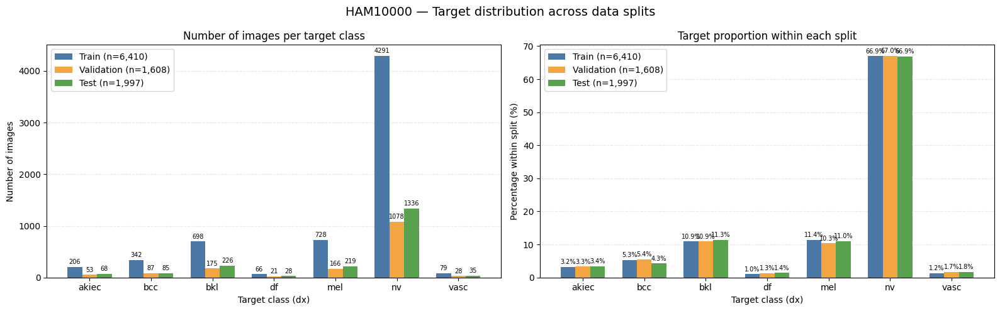

Saved target distribution plot: /content/drive/MyDrive/ham10000_densenet121/target_distribution_train_validation_test.png


In [32]:
# Compare target counts and within-split percentages after the group-aware split.
split_frames = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df,
}

split_counts = pd.DataFrame({
    split_name: frame["dx"].value_counts().reindex(class_names, fill_value=0)
    for split_name, frame in split_frames.items()
}).astype(int)

split_percentages = pd.DataFrame({
    split_name: (
        frame["dx"].value_counts(normalize=True)
        .reindex(class_names, fill_value=0) * 100
    )
    for split_name, frame in split_frames.items()
})

# Display counts and percentages in one table.
distribution_table = pd.DataFrame(index=class_names)
for split_name in split_frames:
    distribution_table[f"{split_name}_count"] = split_counts[split_name]
    distribution_table[f"{split_name}_percent"] = split_percentages[split_name].round(2)

distribution_table.index.name = "Target (dx)"
print("Target distribution by split:")
display(distribution_table)

# Plot raw counts and percentages side by side.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
class_positions = np.arange(len(class_names))
bar_width = 0.24
colors = {"Train": "#4C78A8", "Validation": "#F2A541", "Test": "#59A14F"}

for offset, split_name in zip([-bar_width, 0, bar_width], split_frames):
    counts = split_counts[split_name].values
    percentages = split_percentages[split_name].values
    n_samples = len(split_frames[split_name])

    bars_count = axes[0].bar(
        class_positions + offset,
        counts,
        width=bar_width,
        label=f"{split_name} (n={n_samples:,})",
        color=colors[split_name],
    )
    axes[0].bar_label(bars_count, padding=2, fontsize=7, fmt="%.0f")

    bars_pct = axes[1].bar(
        class_positions + offset,
        percentages,
        width=bar_width,
        label=f"{split_name} (n={n_samples:,})",
        color=colors[split_name],
    )
    axes[1].bar_label(bars_pct, padding=2, fontsize=7, fmt="%.1f%%")

axes[0].set_title("Number of images per target class")
axes[0].set_ylabel("Number of images")
axes[1].set_title("Target proportion within each split")
axes[1].set_ylabel("Percentage within split (%)")

for ax in axes:
    ax.set_xlabel("Target class (dx)")
    ax.set_xticks(class_positions)
    ax.set_xticklabels(class_names)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend()

fig.suptitle("HAM10000 — Target distribution across data splits", fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "target_distribution_train_validation_test.png", dpi=160, bbox_inches="tight")
plt.show()

print("Saved target distribution plot:", OUTPUT_DIR / "target_distribution_train_validation_test.png")


In [33]:
# Keep each image's aspect ratio and pad to a square rather than cutting off lesion borders.
class ResizeWithPad:
    def __init__(self, size):
        self.size = (size, size)
        resampling = getattr(Image, "Resampling", Image)
        self.resample = resampling.BICUBIC

    def __call__(self, image):
        arr = np.asarray(image.convert("RGB"), dtype=np.uint8)
        fill = tuple(np.mean(arr.reshape(-1, 3), axis=0).astype(np.uint8).tolist())
        return ImageOps.pad(image.convert("RGB"), self.size, method=self.resample, color=fill)

imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    ResizeWithPad(256),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

val_test_transform = transforms.Compose([
    ResizeWithPad(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

class HAM10000Dataset(Dataset):
    def __init__(self, frame, transform=None):
        self.paths = frame["image_path"].astype(str).tolist()
        self.labels = frame["label_id"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, self.labels[index]

train_dataset = HAM10000Dataset(train_df, transform=train_transform)
val_dataset = HAM10000Dataset(val_df, transform=val_test_transform)
test_dataset = HAM10000Dataset(test_df, transform=val_test_transform)

train_counts = train_df["dx"].value_counts().reindex(class_names).astype(float)
train_sampler = None
loss_weights = None

if IMBALANCE_STRATEGY == "class_weight":
    # Less aggressive than full inverse-frequency weighting; helps avoid over-correcting rare classes.
    weight_values = (train_counts.max() / train_counts) ** CLASS_WEIGHT_POWER
    weight_values = weight_values / weight_values.mean()
    loss_weights = torch.tensor(weight_values.values, dtype=torch.float32, device=device)
elif IMBALANCE_STRATEGY == "weighted_sampler":
    sample_weights = train_df["dx"].map((1.0 / train_counts).to_dict()).to_numpy(dtype=np.float64)
    train_sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(sample_weights),
        replacement=True,
    )
elif IMBALANCE_STRATEGY != "none":
    raise ValueError("IMBALANCE_STRATEGY must be class_weight, weighted_sampler, or none")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=(train_sampler is None),
    sampler=train_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
)

print("Imbalance strategy:", IMBALANCE_STRATEGY)
if loss_weights is not None:
    display(pd.DataFrame({"class": class_names, "train_count": train_counts.values,
                          "loss_weight": loss_weights.detach().cpu().numpy().round(3)}))
print("Batches per epoch:", len(train_loader))

Imbalance strategy: class_weight


,class,train_count,loss_weight
0,akiec,206.0,1.085
1,bcc,342.0,0.842
2,bkl,698.0,0.589
3,df,66.0,1.917
4,mel,728.0,0.577
5,nv,4291.0,0.238
6,vasc,79.0,1.752


Batches per epoch: 201


In [34]:
# Build DenseNet121 with ImageNet pretrained weights.
def build_densenet121(num_classes, pretrained=True):
    try:
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        net = models.densenet121(weights=weights)
    except AttributeError:
        # Compatibility with older torchvision versions.
        net = models.densenet121(pretrained=pretrained)

    in_features = net.classifier.in_features  # 1024 for DenseNet121
    net.classifier = nn.Sequential(
        nn.Dropout(p=0.30),
        nn.Linear(in_features, num_classes),
    )
    return net

model = build_densenet121(num_classes=len(class_names), pretrained=True).to(device)
criterion = nn.CrossEntropyLoss(weight=loss_weights)
scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

print(model.classifier)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 151MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1024, out_features=7, bias=True)
)
Trainable parameters: 6961031


/tmp/ipykernel_553/194351545.py:19: FutureWarning:

`torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.



### Similarity Matrix (ImageNet-pretrained DenseNet121 embeddings)

Trước khi fine-tune, lấy embedding từ backbone DenseNet121 đã pretrained trên ImageNet cho một mẫu ảnh thuộc **train set** ở mỗi lớp. Tính vector đại diện bằng trung bình embedding theo lớp, sau đó tính cosine similarity giữa các lớp.

- Giá trị càng gần `1` thì embedding đại diện của hai lớp càng giống nhau.
- Đây là phép so sánh đặc trưng từ backbone pretrained, **không phải** kết quả phân loại của model HAM10000 sau huấn luyện.
- Chỉ lấy ảnh từ `train_df`; không dùng validation/test để tạo ma trận này.


Extract pretrained embeddings:   0%|          | 0/7 [00:00<?, ?it/s]

Similarity computed from 210 train images (30 images/class when available).


,akiec,bcc,bkl,df,mel,nv,vasc
akiec,1.000,0.979,0.984,0.967,0.962,0.967,0.935
bcc,0.979,1.000,0.972,0.969,0.962,0.958,0.962
bkl,0.984,0.972,1.000,0.963,0.984,0.973,0.941
df,0.967,0.969,0.963,1.000,0.959,0.961,0.947
mel,0.962,0.962,0.984,0.959,1.000,0.971,0.948
nv,0.967,0.958,0.973,0.961,0.971,1.000,0.922
vasc,0.935,0.962,0.941,0.947,0.948,0.922,1.000


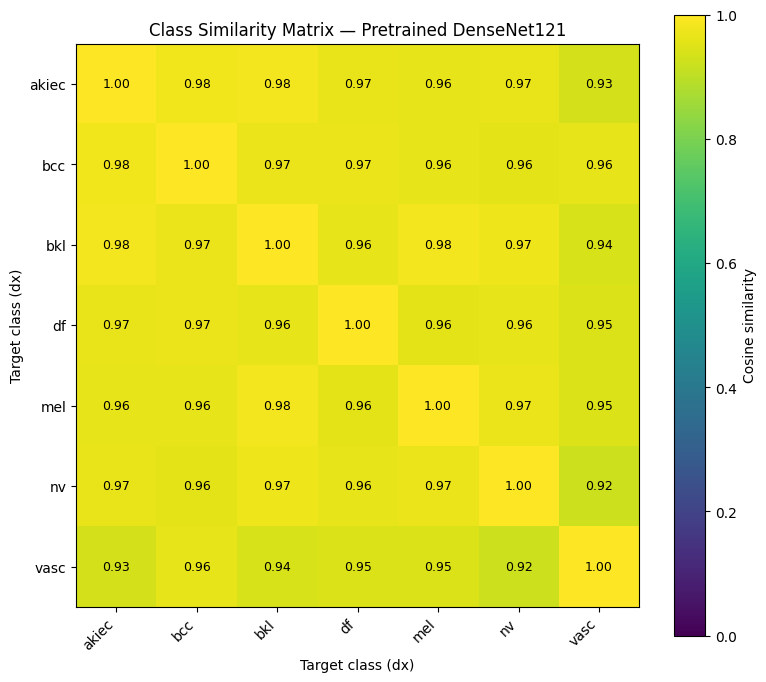

Saved similarity matrix: /content/drive/MyDrive/ham10000_densenet121/densenet121_imagenet_class_similarity.png
Saved similarity values: /content/drive/MyDrive/ham10000_densenet121/densenet121_imagenet_class_similarity.csv


In [35]:
# Build class prototypes from the ImageNet-pretrained DenseNet121 backbone.
# The classifier head is newly initialized, so use model.features only.
SIMILARITY_IMAGES_PER_CLASS = 30
SIMILARITY_BATCH_SIZE = 32

similarity_samples = pd.concat(
    [
        group.sample(
            n=min(SIMILARITY_IMAGES_PER_CLASS, len(group)),
            random_state=SEED,
        )
        for _, group in train_df.groupby("dx", sort=True)
    ],
    ignore_index=True,
)

similarity_dataset = HAM10000Dataset(
    similarity_samples,
    transform=val_test_transform,
)
similarity_loader = DataLoader(
    similarity_dataset,
    batch_size=SIMILARITY_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
)

model.eval()
embedding_batches = []
label_batches = []

with torch.inference_mode():
    for images, labels in tqdm(similarity_loader, desc="Extract pretrained embeddings"):
        images = images.to(device, non_blocking=True)
        feature_maps = model.features(images)
        feature_maps = torch.nn.functional.relu(feature_maps, inplace=False)
        embeddings = torch.nn.functional.adaptive_avg_pool2d(
            feature_maps, output_size=(1, 1)
        ).flatten(1)

        embedding_batches.append(embeddings.cpu())
        label_batches.append(labels.cpu())

all_embeddings = torch.cat(embedding_batches, dim=0).numpy()
all_labels = torch.cat(label_batches, dim=0).numpy()

# Average the normalized image embeddings to form one prototype per class.
class_prototypes = []
for class_idx, class_name in enumerate(class_names):
    class_embeddings = all_embeddings[all_labels == class_idx]
    if len(class_embeddings) == 0:
        raise RuntimeError(f"No sampled training images for class '{class_name}'.")

    class_mean = class_embeddings.mean(axis=0)
    class_mean = class_mean / (np.linalg.norm(class_mean) + 1e-12)
    class_prototypes.append(class_mean)

class_prototypes = np.vstack(class_prototypes)
similarity_matrix = class_prototypes @ class_prototypes.T
similarity_matrix = np.clip(similarity_matrix, -1.0, 1.0)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=class_names,
    columns=class_names,
)
print(
    f"Similarity computed from {len(similarity_samples):,} train images "
    f"({SIMILARITY_IMAGES_PER_CLASS} images/class when available)."
)
display(similarity_df.round(3))
similarity_df.to_csv(OUTPUT_DIR / "densenet121_imagenet_class_similarity.csv")

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(similarity_matrix, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_title("Class Similarity Matrix — Pretrained DenseNet121")
ax.set_xlabel("Target class (dx)")
ax.set_ylabel("Target class (dx)")

for row in range(len(class_names)):
    for col in range(len(class_names)):
        value = similarity_matrix[row, col]
        ax.text(
            col,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value < 0.55 else "black",
            fontsize=9,
        )

fig.colorbar(image, ax=ax, label="Cosine similarity")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "densenet121_imagenet_class_similarity.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved similarity matrix:", OUTPUT_DIR / "densenet121_imagenet_class_similarity.png")
print("Saved similarity values:", OUTPUT_DIR / "densenet121_imagenet_class_similarity.csv")


In [36]:
# Resume only from the latest FULL checkpoint.
# If no full checkpoint exists, start a new training run.
RESUME_TRAINING = True

if RESUME_TRAINING and LAST_CHECKPOINT_PATH.exists():
    print("Full resume is enabled. The latest checkpoint will be loaded in the training cell.")
else:
    print("No full checkpoint found. Training will start from ImageNet-pretrained weights.")

# BEST_MODEL_PATH is only used for evaluation.
# Never use old best-model weights for warm-start.

Full resume is enabled. The latest checkpoint will be loaded in the training cell.


In [37]:
def calculate_metrics(y_true, y_pred):
    """Calculate metrics used for model selection and reporting."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }


def run_one_epoch(
    model, loader, criterion, optimizer=None, freeze_backbone=False,
    progress_desc="Batches"
):
    """Run one complete training or evaluation epoch."""
    is_training = optimizer is not None
    model.train(is_training)

    if is_training and freeze_backbone:
        model.features.eval()

    total_loss = 0.0
    total_samples = 0
    total_correct = 0
    all_targets = []
    all_predictions = []

    batch_bar = tqdm(
        loader,
        desc=progress_desc,
        unit="batch",
        leave=False,
        dynamic_ncols=True,
    )

    for images, labels in batch_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
                logits = model(images)
                loss = criterion(logits, labels)

            if is_training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = labels.size(0)
        predictions = logits.argmax(dim=1)
        batch_correct = (predictions == labels).sum().item()

        total_loss += loss.item() * batch_size
        total_samples += batch_size
        total_correct += batch_correct
        all_targets.extend(labels.detach().cpu().numpy().tolist())
        all_predictions.extend(predictions.detach().cpu().numpy().tolist())

        batch_bar.set_postfix(
            loss=f"{total_loss / max(total_samples, 1):.4f}",
            acc=f"{total_correct / max(total_samples, 1):.4f}",
        )

    metrics = calculate_metrics(all_targets, all_predictions)
    metrics["loss"] = total_loss / max(total_samples, 1)
    return metrics


def make_optimizer(freeze_backbone):
    param_groups = []

    if not freeze_backbone:
        param_groups.append({
            "params": model.features.parameters(),
            "lr": 1e-5
        })

    param_groups.append({
        "params": model.classifier.parameters(),
        "lr": 1e-4 if not freeze_backbone else 1e-3
    })

    return torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)


def atomic_torch_save(payload, destination):
    """Write to a temporary file first to reduce the risk of a partial checkpoint."""
    destination = Path(destination)
    temporary_path = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(payload, temporary_path)
    os.replace(temporary_path, destination)


def capture_rng_state():
    """Capture RNG states so a resumed run can continue reproducibly at epoch boundaries."""
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def restore_rng_state(state):
    if not state:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and state.get("cuda") is not None:
        torch.cuda.set_rng_state_all(state["cuda"])


# ==========================================
# TRAINING CONFIGURATION
# ==========================================

history = []
best_global_score = -float("inf")
best_epoch = None
best_val_accuracy = None
best_val_macro_f1 = None
best_val_balanced_accuracy = None

training_stages = [
    {"name": "head_warmup", "epochs": HEAD_EPOCHS, "freeze": True},
    {"name": "fine_tuning", "epochs": FINE_TUNE_EPOCHS, "freeze": False},
]

# A checkpoint is only safe to resume when it belongs to the same data split and setup.
split_signature_source = (
    split_manifest[["image_id", "lesion_id", "dx", "split"]]
    .astype(str)
    .sort_values(["split", "image_id"])
    .to_csv(index=False)
)
split_signature = hashlib.sha256(split_signature_source.encode("utf-8")).hexdigest()

checkpoint_config = {
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "class_names": list(class_names),
    "split_signature": split_signature,
    "imbalance_strategy": IMBALANCE_STRATEGY,
    "class_weight_power": CLASS_WEIGHT_POWER,
    "weight_decay": WEIGHT_DECAY,
    "head_epochs": HEAD_EPOCHS,
    "fine_tune_epochs": FINE_TUNE_EPOCHS,
    "patience": PATIENCE,
}

# Resume position points to the NEXT epoch to execute.
start_stage_index = 0
start_epoch = 1
resume_optimizer_state = None
resume_scheduler_state = None
resume_scaler_state = None
resume_stage_best_score = -float("inf")
resume_epochs_without_improvement = 0
rng_state_to_restore = None

if RESUME_TRAINING and LAST_CHECKPOINT_PATH.exists():
    try:
        # weights_only=False is required because the checkpoint also stores Python/NumPy RNG states.
        try:
            resume_checkpoint = torch.load(
                LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False
            )
        except TypeError:  # Compatibility with older PyTorch releases.
            resume_checkpoint = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu")

        if resume_checkpoint.get("checkpoint_version") != 1:
            raise RuntimeError("Unsupported checkpoint version. Start a new run or use a matching notebook.")

        saved_config = resume_checkpoint.get("training_config", {})
        if saved_config != checkpoint_config:
            differing_keys = [
                key for key in checkpoint_config
                if saved_config.get(key) != checkpoint_config[key]
            ]
            raise RuntimeError(
                "Checkpoint configuration does not match this run for: "
                + ", ".join(differing_keys)
                + ". Keep the original settings/split or set RESUME_TRAINING = False for a new experiment."
            )

        model.load_state_dict(resume_checkpoint["model_state_dict"])
        history = resume_checkpoint.get("history", [])
        best_global_score = resume_checkpoint.get("best_global_score", -float("inf"))
        best_epoch = resume_checkpoint.get("best_epoch")
        best_val_accuracy = resume_checkpoint.get("best_val_accuracy")
        best_val_macro_f1 = resume_checkpoint.get("best_val_macro_f1")
        best_val_balanced_accuracy = resume_checkpoint.get("best_val_balanced_accuracy")

        start_stage_index = int(resume_checkpoint["next_stage_index"])
        start_epoch = int(resume_checkpoint["next_epoch"])
        rng_state_to_restore = resume_checkpoint.get("rng_state")

        # Restore optimizer/scheduler only when continuing inside the same stage.
        if start_stage_index == int(resume_checkpoint["stage_index"]):
            resume_optimizer_state = resume_checkpoint.get("optimizer_state_dict")
            resume_scheduler_state = resume_checkpoint.get("scheduler_state_dict")
            resume_scaler_state = resume_checkpoint.get("scaler_state_dict")
            resume_stage_best_score = resume_checkpoint.get("stage_best_score", -float("inf"))
            resume_epochs_without_improvement = int(
                resume_checkpoint.get("epochs_without_improvement", 0)
            )

        print(
            f"Resumed checkpoint: completed {len(history)} epoch(s); "
            f"next stage index={start_stage_index}, next epoch={start_epoch}."
        )

    except Exception as exc:
        raise RuntimeError(
            f"Could not resume from {LAST_CHECKPOINT_PATH}: {exc}"
        ) from exc
elif (
    RESUME_TRAINING
    and LAST_CHECKPOINT_PATH.exists()
    and BEST_MODEL_PATH.exists()
):
    # Backward compatibility: older notebook versions saved only best model weights.
    # This is a warm start; optimizer/scheduler/epoch progress cannot be recovered.
    try:
        try:
            old_best_checkpoint = torch.load(
                BEST_MODEL_PATH, map_location="cpu", weights_only=False
            )
        except TypeError:
            old_best_checkpoint = torch.load(BEST_MODEL_PATH, map_location="cpu")
        model.load_state_dict(old_best_checkpoint["model_state_dict"])
        print(
            "Loaded weights from the previous best model. This is a WARM START, "
            "not an exact resume: optimizer, scheduler and epoch progress are reset."
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not load the previous best model from {BEST_MODEL_PATH}: {exc}"
        ) from exc
else:
    print("Starting a new training run from ImageNet-pretrained DenseNet121 weights.")

# Restore RNG immediately before creating the next training DataLoader iterator.
restore_rng_state(rng_state_to_restore)


# ==========================================
# TRAINING LOOP
# ==========================================

for stage_index, stage in enumerate(training_stages):
    if stage_index < start_stage_index:
        continue

    freeze_backbone = stage["freeze"]

    for parameter in model.features.parameters():
        parameter.requires_grad = not freeze_backbone
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    optimizer = make_optimizer(freeze_backbone)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
    )

    # Only restore these states when continuing in the exact same training stage.
    if stage_index == start_stage_index and resume_optimizer_state is not None:
        optimizer.load_state_dict(resume_optimizer_state)
        scheduler.load_state_dict(resume_scheduler_state)
        if resume_scaler_state is not None:
            scaler.load_state_dict(resume_scaler_state)
        stage_best_score = resume_stage_best_score
        epochs_without_improvement = resume_epochs_without_improvement
        epoch_start = start_epoch
        print(f"Restored optimizer/scheduler state for stage '{stage['name']}'.")
    else:
        stage_best_score = -float("inf")
        epochs_without_improvement = 0
        epoch_start = start_epoch if stage_index == start_stage_index else 1

    print(
        f"\n===== Stage: {stage['name']} | "
        f"freeze_backbone={freeze_backbone} | starting epoch={epoch_start} ====="
    )

    epoch_bar = tqdm(
        range(epoch_start, stage["epochs"] + 1),
        desc=f"Epochs — {stage['name']}",
        unit="epoch",
        dynamic_ncols=True,
    )

    for epoch in epoch_bar:
        start_time = time.time()

        train_metrics = run_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            freeze_backbone=freeze_backbone,
            progress_desc=f"Train {epoch}/{stage['epochs']}",
        )

        val_metrics = run_one_epoch(
            model,
            val_loader,
            criterion,
            optimizer=None,
            progress_desc=f"Valid {epoch}/{stage['epochs']}",
        )

        # Use the same balanced selection score described in the notebook overview.
        val_selection_score = 0.5 * val_metrics["accuracy"] + 0.5 * val_metrics["macro_f1"]
        scheduler.step(val_selection_score)

        epoch_record = {
            "stage": stage["name"],
            "stage_epoch": epoch,
            "epoch": len(history) + 1,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"],
            "train_balanced_accuracy": train_metrics["balanced_accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "selection_score": val_selection_score,
        }
        history.append(epoch_record)

        elapsed = time.time() - start_time
        epoch_bar.set_postfix(
            train_loss=f"{train_metrics['loss']:.4f}",
            val_loss=f"{val_metrics['loss']:.4f}",
            val_acc=f"{val_metrics['accuracy']:.4f}",
            val_f1=f"{val_metrics['macro_f1']:.4f}",
        )

        print(
            f"{stage['name']} | epoch {epoch:02d}/{stage['epochs']} | "
            f"train loss {train_metrics['loss']:.4f} | "
            f"val loss {val_metrics['loss']:.4f} | "
            f"val acc {val_metrics['accuracy']:.4f} | "
            f"val macro-F1 {val_metrics['macro_f1']:.4f} | "
            f"selection score {val_selection_score:.4f} | {elapsed:.1f}s"
        )

        # Save the best model separately for final evaluation.
        if val_selection_score > best_global_score:
            best_global_score = val_selection_score
            best_epoch = len(history)
            best_val_accuracy = val_metrics["accuracy"]
            best_val_macro_f1 = val_metrics["macro_f1"]
            best_val_balanced_accuracy = val_metrics["balanced_accuracy"]

            best_checkpoint = {
                "model_state_dict": {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                },
                "class_names": list(class_names),
                "class_to_idx": dict(class_to_idx),
                "image_size": IMAGE_SIZE,
                "best_epoch": best_epoch,
                "selection_score": best_global_score,
                "best_val_accuracy": best_val_accuracy,
                "best_val_macro_f1": best_val_macro_f1,
                "best_val_balanced_accuracy": best_val_balanced_accuracy,
            }
            atomic_torch_save(best_checkpoint, BEST_MODEL_PATH)
            print(
                f"Best model saved | score={best_global_score:.4f} | "
                f"accuracy={best_val_accuracy:.4f} | macro-F1={best_val_macro_f1:.4f}"
            )

        # Update stage-level early-stopping state.
        if val_selection_score > stage_best_score + 1e-4:
            stage_best_score = val_selection_score
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        early_stopping_triggered = epochs_without_improvement >= PATIENCE
        stage_finished = early_stopping_triggered or epoch >= stage["epochs"]

        if stage_finished:
            next_stage_index = stage_index + 1
            next_epoch = 1
        else:
            next_stage_index = stage_index
            next_epoch = epoch + 1

        # Save history and the FULL latest training state after every completed epoch.
        history_df = pd.DataFrame(history)
        history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

        latest_checkpoint = {
            "checkpoint_version": 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "stage_index": stage_index,
            "stage_name": stage["name"],
            "next_stage_index": next_stage_index,
            "next_epoch": next_epoch,
            "stage_best_score": stage_best_score,
            "epochs_without_improvement": epochs_without_improvement,
            "history": history,
            "best_global_score": best_global_score,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_accuracy,
            "best_val_macro_f1": best_val_macro_f1,
            "best_val_balanced_accuracy": best_val_balanced_accuracy,
            "training_config": checkpoint_config,
            "rng_state": capture_rng_state(),
        }
        atomic_torch_save(latest_checkpoint, LAST_CHECKPOINT_PATH)
        print("Latest training checkpoint saved:", LAST_CHECKPOINT_PATH)

        if early_stopping_triggered:
            print(
                f"Early stopping stage '{stage['name']}' at epoch {epoch} "
                f"after {PATIENCE} epochs without improvement."
            )
            break

    # Do not reuse optimizer/scheduler states when moving to another stage.
    resume_optimizer_state = None
    resume_scheduler_state = None
    resume_scaler_state = None
    resume_stage_best_score = -float("inf")
    resume_epochs_without_improvement = 0
    start_epoch = 1


# ==========================================
# SAVE FINAL TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print("\n========== TRAINING STATUS ==========")
if start_stage_index >= len(training_stages) or (
    LAST_CHECKPOINT_PATH.exists()
    and 'latest_checkpoint' in locals()
    and latest_checkpoint["next_stage_index"] >= len(training_stages)
):
    print("All configured training stages have been completed.")
else:
    print("Training stopped before all configured stages were completed.")
print("Best selection score:", best_global_score)
print("Best validation accuracy:", best_val_accuracy)
print("Best validation Macro-F1:", best_val_macro_f1)
print("Best epoch:", best_epoch)
print("Best model saved at:", BEST_MODEL_PATH)
print("Latest resume checkpoint:", LAST_CHECKPOINT_PATH)
print("History saved at:", OUTPUT_DIR / "training_history.csv")

Resumed checkpoint: completed 30 epoch(s); next stage index=2, next epoch=1.

========== TRAINING STATUS ==========
All configured training stages have been completed.
Best selection score: 0.7692561808348453
Best validation accuracy: 0.8376865671641791
Best validation Macro-F1: 0.7008257945055113
Best epoch: 30
Best model saved at: /content/drive/MyDrive/ham10000_densenet121/densenet121_ham10000_best.pth
Latest resume checkpoint: /content/drive/MyDrive/ham10000_densenet121/densenet121_ham10000_last.pth
History saved at: /content/drive/MyDrive/ham10000_densenet121/training_history.csv


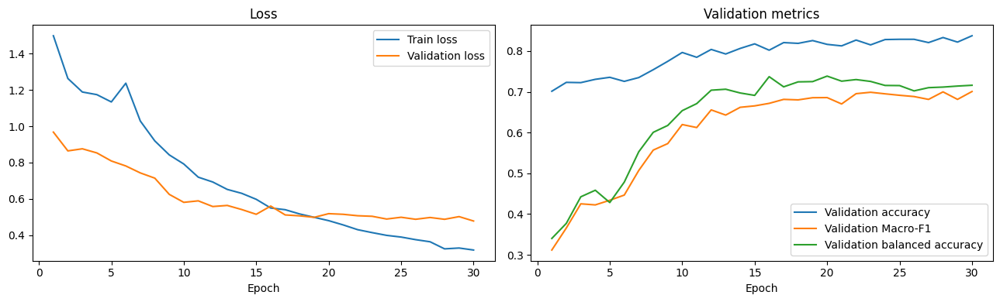

Best model loaded successfully!


Test evaluation:   0%|          | 0/63 [00:00<?, ?it/s]

/tmp/ipykernel_553/3539687952.py:38: FutureWarning:

`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.



Probability matrix shape: (1997, 7)

===== FINAL TEST RESULTS =====
Accuracy:          0.8247
Macro-F1:          0.7101
Balanced Accuracy: 0.7173

Classification report:
              precision    recall  f1-score   support

       akiec     0.5672    0.5588    0.5630        68
         bcc     0.6593    0.7059    0.6818        85
         bkl     0.6151    0.7566    0.6786       226
          df     0.7200    0.6429    0.6792        28
         mel     0.6519    0.4703    0.5464       219
          nv     0.9141    0.9154    0.9147      1336
        vasc     0.8500    0.9714    0.9067        35

    accuracy                         0.8247      1997
   macro avg     0.7111    0.7173    0.7101      1997
weighted avg     0.8250    0.8247    0.8223      1997



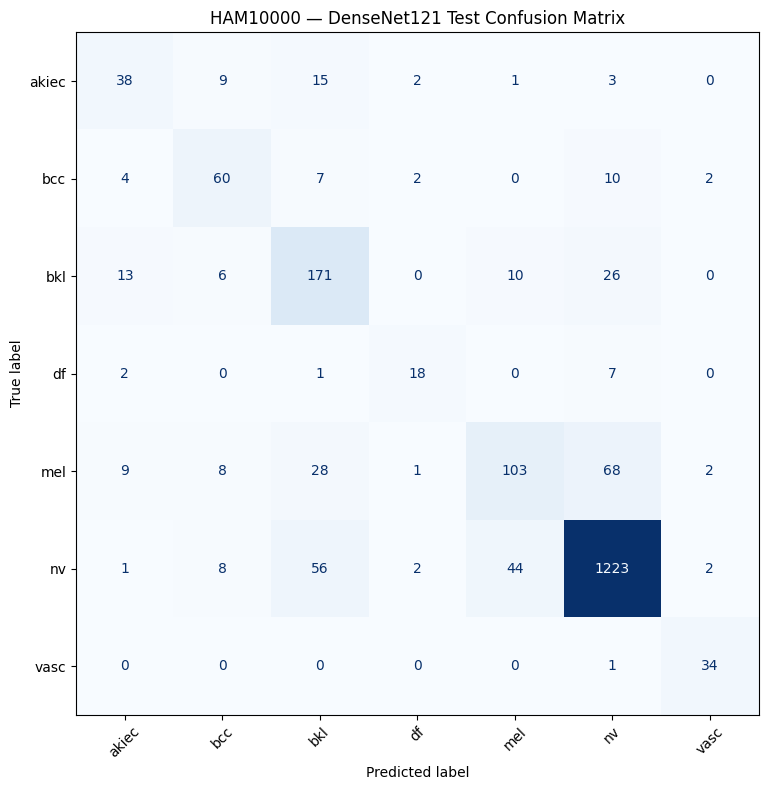

,accuracy,macro_f1,balanced_accuracy,best_validation_score,best_epoch
0,0.824737,0.71006,0.717338,0.769256,30


Artifacts saved in: /content/drive/MyDrive/ham10000_densenet121


In [41]:
# Plot training history and evaluate the selected checkpoint exactly once on the held-out test set.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["val_accuracy"], label="Validation accuracy")
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], label="Validation Macro-F1")
axes[1].plot(history_df["epoch"], history_df["val_balanced_accuracy"], label="Validation balanced accuracy")
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Load the trusted checkpoint saved by your own training code
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best model loaded successfully!")

# Manually run evaluation to extract both y_true and y_pred
y_test = []
y_pred = []
test_probabilities = []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Test evaluation"):
        images = images.to(device)

        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = model(images)

        # Calculate probabilities
        batch_probabilities = torch.softmax(logits, dim=1)

        # Get predicted classes
        predictions = logits.argmax(dim=1)

        y_test.extend(labels.cpu().numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())

        # Save probabilities for every test image
        test_probabilities.extend(
            batch_probabilities.cpu().numpy().tolist()
        )

# Convert to NumPy array
test_probabilities = np.asarray(test_probabilities)

print("Probability matrix shape:", test_probabilities.shape)

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred)
}

print("\n===== FINAL TEST RESULTS =====")
print(f"Accuracy:          {test_metrics['accuracy']:.4f}")
print(f"Macro-F1:          {test_metrics['macro_f1']:.4f}")
print(f"Balanced Accuracy: {test_metrics['balanced_accuracy']:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0,
))

report_dict = classification_report(
    y_test, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(report_dict).T.to_csv(OUTPUT_DIR / "test_classification_report.csv")

cm = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))
fig, ax = plt.subplots(figsize=(9, 8))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display_cm.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d", colorbar=False)
ax.set_title("HAM10000 — DenseNet121 Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Save test metrics in a compact file.
test_summary = pd.DataFrame([{
    "accuracy": test_metrics["accuracy"],
    "macro_f1": test_metrics["macro_f1"],
    "balanced_accuracy": test_metrics["balanced_accuracy"],
    "best_validation_score": checkpoint["selection_score"],
    "best_epoch": checkpoint["best_epoch"],
}])
test_summary.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
display(test_summary)
print("Artifacts saved in:", OUTPUT_DIR)

###Visualization Wrong Predict

MISCLASSIFIED IMAGES BY TARGET CLASS


,Target,Total test images,Incorrect predictions
0,akiec,68,30
1,bcc,85,25
2,bkl,226,55
3,df,28,10
4,mel,219,116
5,nv,1336,113
6,vasc,35,1


/tmp/ipykernel_553/4179840313.py:162: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



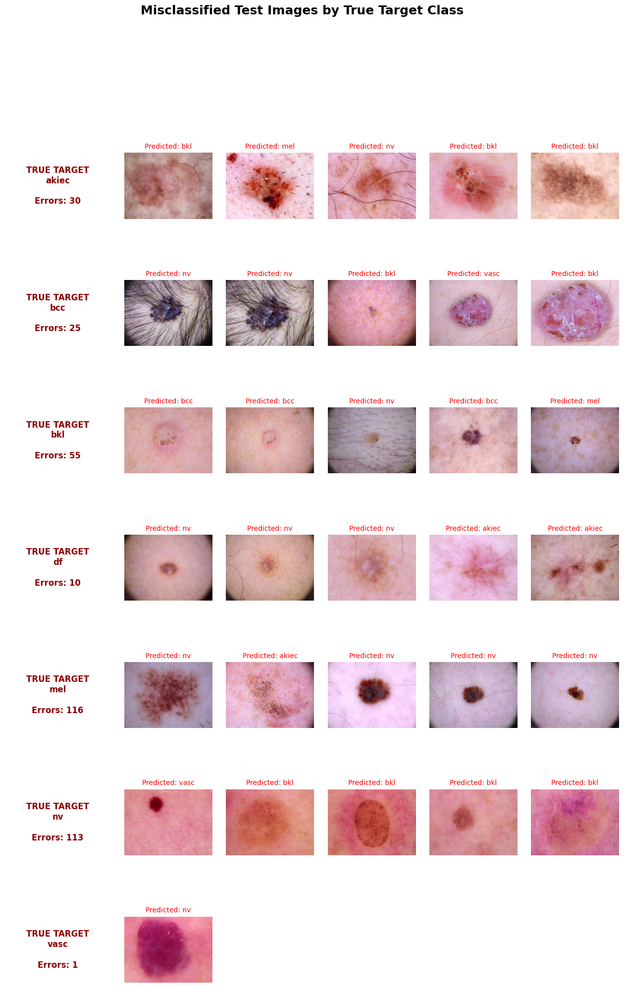

In [48]:
# ==========================================
# MISCLASSIFIED IMAGES GROUPED BY TRUE CLASS
# ==========================================

# Build prediction dataframe
# No need for test_probabilities in this cell

test_results = test_df.reset_index(drop=True).copy()

assert len(test_results) == len(y_test) == len(y_pred)

test_results["true_label"] = [
    idx_to_class[int(i)] for i in y_test
]

test_results["predicted_label"] = [
    idx_to_class[int(i)] for i in y_pred
]

test_results["is_correct"] = (
    test_results["true_label"] == test_results["predicted_label"]
)

# Get incorrect predictions
misclassified = test_results[
    ~test_results["is_correct"]
].copy()

# Configuration
MAX_IMAGES_PER_CLASS = 8
N_CLASSES = len(class_names)

# Count errors for each actual target
error_counts = (
    misclassified["true_label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("=" * 60)
print("MISCLASSIFIED IMAGES BY TARGET CLASS")
print("=" * 60)

display(pd.DataFrame({
    "Target": class_names,
    "Total test images": [
        (test_results["true_label"] == c).sum()
        for c in class_names
    ],
    "Incorrect predictions": error_counts.values
}))





/tmp/ipykernel_553/2460505898.py:107: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



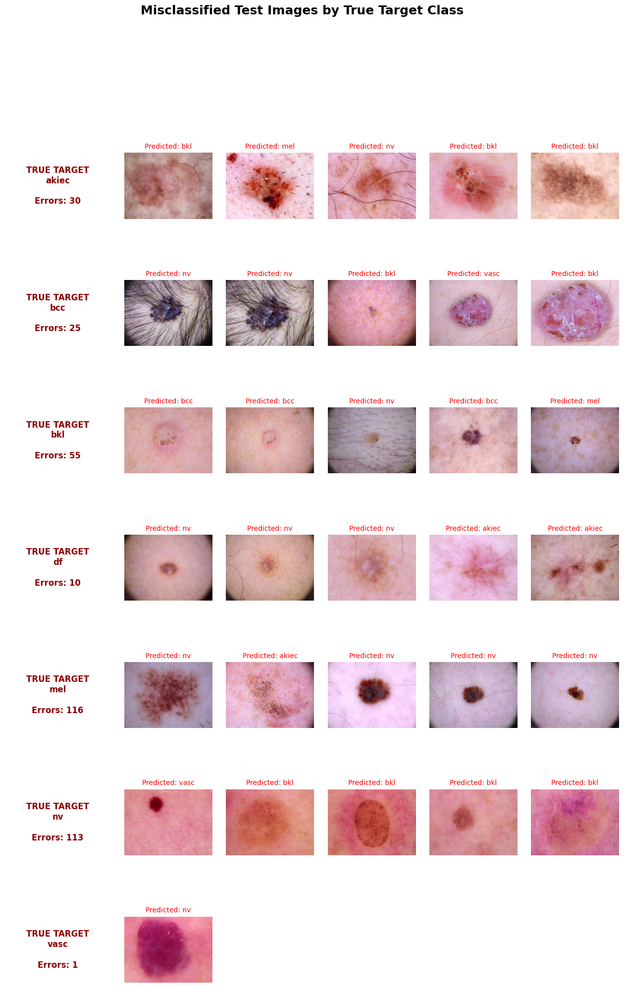

In [49]:

# ==========================================
# MISCLASSIFIED IMAGES GROUPED BY TRUE TARGET
# ==========================================

# Build prediction dataframe
test_results = test_df.reset_index(drop=True).copy()

assert len(test_results) == len(y_test) == len(y_pred)

test_results["true_label"] = [
    idx_to_class[int(i)] for i in y_test
]

test_results["predicted_label"] = [
    idx_to_class[int(i)] for i in y_pred
]

# Extract incorrect predictions
misclassified = test_results[
    test_results["true_label"] != test_results["predicted_label"]
].copy()

# Configuration
MAX_IMAGES_PER_CLASS = 5
N_CLASSES = len(class_names)
N_COLS = MAX_IMAGES_PER_CLASS

# Create figure with an extra column for target names
fig = plt.figure(
    figsize=(16, 3.2 * N_CLASSES)
)

gs = fig.add_gridspec(
    N_CLASSES,
    N_COLS + 1,
    width_ratios=[1.2] + [1] * N_COLS,
    hspace=0.4,
    wspace=0.15
)

for row_idx, class_name in enumerate(class_names):

    class_errors = misclassified[
        misclassified["true_label"] == class_name
    ].head(MAX_IMAGES_PER_CLASS)

    total_errors = (
        misclassified["true_label"] == class_name
    ).sum()

    # Target name column
    label_ax = fig.add_subplot(gs[row_idx, 0])
    label_ax.axis("off")

    label_ax.text(
        0.5, 0.5,
        f"TRUE TARGET\n{class_name}\n\n"
        f"Errors: {total_errors}",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="darkred"
    )

    # Display incorrect images
    for col_idx in range(N_COLS):

        ax = fig.add_subplot(gs[row_idx, col_idx + 1])

        if col_idx < len(class_errors):

            image_row = class_errors.iloc[col_idx]

            with Image.open(image_row["image_path"]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(
                f"Predicted: {image_row['predicted_label']}",
                fontsize=10,
                color="red"
            )

        else:
            ax.axis("off")
            continue

        ax.axis("off")

    # Handle classes without incorrect predictions
    if len(class_errors) == 0:
        label_ax.text(
            0.5, 0.2,
            "No errors",
            ha="center",
            fontsize=9,
            color="green"
        )

fig.suptitle(
    "Misclassified Test Images by True Target Class",
    fontsize=18,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "misclassified_images_by_target.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [39]:
# Optional: predict the top-k classes for one new dermoscopic image.
def predict_skin_lesion(image_path, top_k=3):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
    input_tensor = val_test_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)[0]

    k = min(top_k, len(class_names))
    scores, indices = torch.topk(probabilities, k=k)
    return pd.DataFrame({
        "class": [idx_to_class[int(i)] for i in indices.cpu().numpy()],
        "probability": scores.cpu().numpy(),
    })

# Example:
# predict_skin_lesion("/path/to/one_skin_image.jpg", top_k=3)